# Julia から Wolfram Engine を呼び出す — 線形代数（行列）を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します。

Julia は行列計算が得意ですが，結果は基本的に小数（近似値）です。Wolfram の**厳密な値・文字式**を Julia の行列として受け取り，計算と図示に使います。

- 行列の積・行列式・逆行列（厳密な分数，文字を含む行列）
- 連立 1 次方程式
- 固有値・固有ベクトル・対角化（$\sqrt{\ }$ を含む厳密な値）
- 行列の $n$ 乗 → $n$ の式を **Julia の関数**にする（漸化式への応用）
- 1 次変換（回転・拡大）を図示する

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数は `wolfram_common.jl` にまとめてあります（このノートブックと同じフォルダに置きます）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "SpecialFunctions", "Plots"])
# Pkg.add(url="https://github.com/ujimushi/PlotsGRBackendFontJaEmoji.jl")   # グラフの日本語表示用

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数
using LinearAlgebra               # Julia の det, inv, eigen など
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする

## 1. 基本：Wolfram と Julia の行列

| | Wolfram | Julia |
|---|---|---|
| 行列 | `{{1, 2}, {3, 4}}`（行のリスト） | `[1 2; 3 4]` |
| 積 | `A . B`（ピリオド） | `A * B` |
| 行列式 | `Det[A]` | `det(A)` |
| 逆行列 | `Inverse[A]` | `inv(A)` |
| 転置 | `Transpose[A]` | `A'` または `transpose(A)` |
| $n$ 乗 | `MatrixPower[A, n]` | `A^n` |

In [3]:
weval(W`Inverse[{{1, 2}, {3, 4}}]`)            # 厳密な分数

W`List[List[-2, 1], List[Rational[3, 2], Rational[-1, 2]]]`

In [4]:
inv([1 2; 3 4]), inv([1 2; 3 4] .// 1)         # Julia：小数になる／分数 // にすれば厳密

([-1.9999999999999996 0.9999999999999998; 1.4999999999999998 -0.4999999999999999], Rational{Int64}[-2 1; 3//2 -1//2])

## 2. このノートブックで使う関数

- `wmat(A)`：Julia の行列 → Wolfram 言語の文字列（Julia から Wolfram へ渡す）
- `mtex(w)`：Wolfram の行列 → 行列の形の $\LaTeX$
- `calc("式")`：「入力した式 = 結果」を行列の形で表示して，結果を返す
- 共通ファイルの `to_matrix(w)`：Wolfram の行列 → Julia の行列，`to_matrix_function(w, :x)`：行列を返す Julia の関数

In [5]:
# Julia の数 → Wolfram 言語の文字列
wnum(x::Integer)  = string(x)
wnum(x::Rational) = isone(denominator(x)) ? string(numerator(x)) : "$(numerator(x))/$(denominator(x))"
wnum(x::Real)     = string(x)

# Julia のベクトル・行列 → Wolfram 言語の文字列（{{1, 2}, {3, 4}} の形）
wvec(v::AbstractVector) = "{" * join(wnum.(v), ", ") * "}"
wmat(A::AbstractMatrix) = "{" * join((wvec(A[i, :]) for i in axes(A, 1)), ", ") * "}"

# リストを行列の形の LaTeX にする（行列・ベクトル以外はそのまま）
mtex(w) = islist(w) ? tex(W"MatrixForm"(w)) : tex(w)

# 「入力した式 = 結果」を表示して，結果（Wolfram の式）を返す。lhs で左辺の LaTeX を指定できる
function calc(cmd::AbstractString; lhs=nothing, simplify=false)
    res = weval(wparse(cmd))
    simplify && (res = weval(W"FullSimplify"(res)))
    showtex((lhs === nothing ? heldtex(cmd) : lhs) * " = " * mtex(res))
    return res
end

calc (generic function with 1 method)

In [6]:
A = [2 1; 1 3]
wmat(A), wmat([1//2 3; 0 -2//3])

("{{2, 1}, {1, 3}}", "{{1/2, 3}, {0, -2/3}}")

In [7]:
Aw = calc(wmat(A); lhs="A")                    # Julia の行列を Wolfram に渡して表示
to_matrix(Aw)                                  # Wolfram の行列 → Julia の行列

2×2 Matrix{Int64}:
 2  1
 1  3

## 3. 行列の計算

In [8]:
a = "{{2, 1}, {1, 3}}"; b = "{{1, -1}, {2, 0}}"

calc("$a + $b"; lhs="A + B")
ABw = calc("$a.$b"; lhs="AB")
BAw = calc("$b.$a"; lhs="BA")
calc("$a.$b - $b.$a"; lhs="AB - BA")           # 行列の積は交換できない
calc("$a.{x, y}"; lhs="A \\begin{pmatrix} x \\\\ y \\end{pmatrix}")
calc("MatrixPower[$a, 5]"; lhs="A^5")

to_matrix(ABw), [2 1; 1 3] * [1 -1; 2 0]       # Julia の計算と一致

([4 -2; 7 -1], [4 -2; 7 -1])

### 行列式と逆行列

Wolfram は分数のまま厳密に計算します。Julia の `inv` は小数ですが，成分を分数（`//`）にしておけば Julia でも厳密です。

In [9]:
m = "{{2, 1, 1}, {1, 3, 2}, {1, 0, 0}}"
M = to_matrix(weval(wparse(m)))

calc("Det[$m]"; lhs="\\det M")
Miw = calc("Inverse[$m]"; lhs="M^{-1}")
calc("$m.Inverse[$m]"; lhs="M M^{-1}")

Mi = to_matrix(Miw)                            # 成分は分数（Rational）
Mi, M * Mi

([0 0 1; -2 1 3; 3 -1 -5], [1 0 0; 0 1 0; 0 0 1])

In [10]:
inv(M)                                         # Julia の inv は小数（丸め誤差を含む）

3×3 Matrix{Float64}:
  5.55112e-17  -2.22045e-17   1.0
 -2.0           1.0           3.0
  3.0          -1.0          -5.0

### 文字を含む行列 → Julia の関数

2 次の行列式と逆行列の公式を，文字のまま求めます。`to_matrix_function` で行列を返す Julia の関数にできます。

In [11]:
g = "{{a, b}, {c, d}}"
dw = calc("Det[$g]"; lhs="\\det \\begin{pmatrix} a & b \\\\ c & d \\end{pmatrix}")
iw = calc("Inverse[$g]"; lhs="\\begin{pmatrix} a & b \\\\ c & d \\end{pmatrix}^{-1}")
calc("Simplify[Inverse[$g] Det[$g]]"; lhs="(ad - bc)\\begin{pmatrix} a & b \\\\ c & d \\end{pmatrix}^{-1}")

inv2 = to_matrix_function(iw, :a, :b, :c, :d)
inv2(2, 1, 1, 3), inv2(2 // 1, 1, 1, 3)        # 整数を入れると分数で厳密に返る

(Rational{Int64}[3//5 -1//5; -1//5 2//5], Rational{Int64}[3//5 -1//5; -1//5 2//5])

In [12]:
# 3 次の行列式（サラスの方法の式）
calc("Det[{{a, b, c}, {p, q, r}, {x, y, z}}]"; lhs="\\det \\begin{pmatrix} a & b & c \\\\ p & q & r \\\\ x & y & z \\end{pmatrix}");

### ケーリー・ハミルトンの定理

$A = \begin{pmatrix} a & b \\ c & d \end{pmatrix}$ に対して $A^2 - (a + d)A + (ad - bc)E = O$ が成り立ちます。

In [13]:
calc("CharacteristicPolynomial[$g, t]"; lhs="\\det(A - tE)")
calc("Simplify[$g.$g - (a + d) $g + (a d - b c) IdentityMatrix[2]]"; lhs="A^2 - (a+d)A + (ad-bc)E");

## 4. 連立 1 次方程式

$A\vec x = \vec b$ を `LinearSolve` で解きます。Julia では `A \ b` です。

In [14]:
A3 = [2 1 -1; 1 -1 2; 3 2 1]; b3 = [3, 4, 10]

xw = calc("LinearSolve[$(wmat(A3)), $(wvec(b3))]"; lhs="\\vec x")
x = to_value(xw)

x, A3 * x, A3 \ b3                              # 厳密解，検算（b に一致），Julia の解（小数）

(Rational{Int64}[17//10, 3//2, 19//10], Rational{Int64}[3, 4, 10], [1.7, 1.5000000000000002, 1.9])

### 解をもつ条件（文字を含む連立方程式）

$\begin{cases} x + ky = 1 \\ kx + y = 1 \end{cases}$ の解は $k$ の値によって変わります。`Reduce` は場合分けをして答えます。

In [15]:
rw = weval(W`Reduce[{x + k y == 1, k x + y == 1}, {x, y}]`)
showtex(replace(tex(rw), "\\lor" => "\\ \\text{または}\\ ", "\\land" => "\\ \\text{かつ}\\ "))

calc("Det[{{1, k}, {k, 1}}]"; lhs="\\det \\begin{pmatrix} 1 & k \\\\ k & 1 \\end{pmatrix}")
calc("MatrixRank[{{1, 1}, {1, 1}}]"; lhs="k = 1 \\text{ のときの階数}");

### 掃き出し法

`RowReduce` は拡大係数行列を簡約な形（階段行列）に変形します。

In [16]:
calc("RowReduce[{{2, 1, -1, 3}, {1, -1, 2, 4}, {3, 2, 1, 10}}]"; lhs="\\left(A \\mid \\vec b\\right) \\text{ を掃き出した結果}")
calc("RowReduce[{{1, 2, 3, 6}, {2, 4, 6, 12}, {1, 1, 1, 3}}]"; lhs="\\text{解が無数にある例}")
calc("NullSpace[{{1, 2, 3}, {2, 4, 6}, {1, 1, 1}}]"; lhs="A\\vec x = \\vec 0 \\text{ の解の基底}");

## 5. 固有値・固有ベクトル

$A\vec v = \lambda\vec v$ を満たす $\lambda$（固有値）と $\vec v \neq \vec 0$（固有ベクトル）を求めます。  
Wolfram は $\sqrt{\ }$ を含む厳密な値を返します。Julia の `eigen` は小数です。

In [17]:
s = "{{2, 1}, {1, 3}}"
calc("CharacteristicPolynomial[$s, t]"; lhs="\\det(A - tE)")
λw = calc("Eigenvalues[$s]"; lhs="\\lambda")
vw = calc("Eigenvectors[$s]"; lhs="\\text{固有ベクトル（各行）}")

λ = to_value(λw); V = to_value(vw)
λ, V

([3.618033988749895, 1.381966011250105], [[0.6180339887498949, 1.0], [-1.618033988749895, 1.0]])

In [18]:
# 検算（A v = λ v）と，Julia の eigen との比較
S = [2 1; 1 3]
for (l, v) in zip(λ, V)
    println("λ = ", l, " :  A v = ", S * v, "    λ v = ", l * v)
end
eigen(S).values

λ = 3.618033988749895 :  A v = [2.23606797749979, 3.618033988749895]    λ v = [2.23606797749979, 3.618033988749895]
λ = 1.381966011250105 :  A v = [-2.23606797749979, 1.381966011250105]    λ v = [-2.23606797749979, 1.381966011250105]


2-element Vector{Float64}:
 1.381966011250105
 3.618033988749895

### 固有ベクトルの向きは変わらない

1 次変換 $\vec x \mapsto A\vec x$ で単位円上の点がどこに移るかを描きます。固有ベクトルの方向だけは，向きが変わらず $\lambda$ 倍になります。

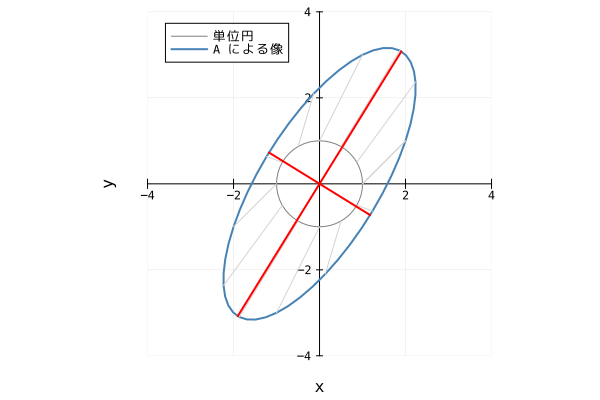

In [19]:
θs = range(0, 2π; length=49)
plot(cos.(θs), sin.(θs); aspect_ratio=1, color=:gray, label="単位円", xlabel="x", ylabel="y",
     xlims=(-4, 4), ylims=(-4, 4), framestyle=:origin, legend=:topleft)
img = [S * [cos(t), sin(t)] for t in θs]
plot!(first.(img), last.(img); color=:steelblue, lw=2, label="A による像")
for t in θs[1:4:end]                                    # 円上の点とその像を線で結ぶ
    p = [cos(t), sin(t)]; q = S * p
    plot!([p[1], q[1]], [p[2], q[2]]; color=:lightgray, label="")
end
for (l, v) in zip(λ, V)                                 # 固有ベクトルの方向
    u = v / norm(v)
    plot!([-l * u[1], l * u[1]], [-l * u[2], l * u[2]]; color=:red, lw=2, label="")
end
plot!()

### 対角化と行列の $n$ 乗

固有ベクトルを列に並べた行列 $P$ を使うと，$P^{-1}AP = D$（対角行列）になります。  
これを使うと $A^n = P D^n P^{-1}$ が $n$ の式で求まります。Wolfram では `MatrixPower[A, n]` で直接求められます。

In [20]:
t2 = "{{1, 2}, {3, 2}}"
calc("Eigenvalues[$t2]"; lhs="\\lambda")
Pw = calc("Transpose[Eigenvectors[$t2]]"; lhs="P")
calc("Inverse[Transpose[Eigenvectors[$t2]]].$t2.Transpose[Eigenvectors[$t2]]"; lhs="P^{-1} A P")
Anw = calc("MatrixPower[$t2, n]"; lhs="A^n", simplify=true)

An = to_matrix_function(Anw, :n)                # n -> A^n（整数 n なら厳密）
An(5), [1 2; 3 2]^5

([409 410; 615 614], [409 410; 615 614])

In [21]:
all(An(n) == [1 2; 3 2]^n for n in 0:15)       # n = 0〜15 で Julia の A^n と一致するか

true

### 応用：連立漸化式とフィボナッチ数列

$\begin{pmatrix} a_{n+1} \\ b_{n+1} \end{pmatrix} = A \begin{pmatrix} a_n \\ b_n \end{pmatrix}$ の一般項は $A^n$ から求まります。  
フィボナッチ数列は $\begin{pmatrix} F_{n+1} \\ F_n \end{pmatrix} = \begin{pmatrix} 1 & 1 \\ 1 & 0 \end{pmatrix}^n \begin{pmatrix} 1 \\ 0 \end{pmatrix}$ です。

In [22]:
calc("Eigenvalues[{{1, 1}, {1, 0}}]"; lhs="\\lambda")                   # 黄金比が現れる
Fnw = calc("FullSimplify[MatrixPower[{{1, 1}, {1, 0}}, n].{1, 0}]"; lhs="\\begin{pmatrix} F_{n+1} \\\\ F_n \\end{pmatrix}")

binet = to_function(Fnw.args[2], :n)            # ビネの公式（√5 を含むので小数になる）
[round(Int, binet(n)) for n in 1:15], [([1 1; 1 0]^n)[2, 1] for n in 1:15]

([1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610], [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610])

In [23]:
# 連立漸化式 a_{n+1} = a_n + 2 b_n,  b_{n+1} = 3 a_n + 2 b_n,  a_1 = 1, b_1 = 0
abw = calc("FullSimplify[MatrixPower[$t2, n - 1].{1, 0}]"; lhs="\\begin{pmatrix} a_n \\\\ b_n \\end{pmatrix}")
ab = to_function(abw, :n)

seq = [[1, 0]]
for _ in 1:7
    push!(seq, [1 2; 3 2] * seq[end])           # 漸化式どおりに計算
end
[ab(n) for n in 1:8] == seq

true

## 6. 1 次変換

### 回転

原点のまわりに $\theta$ 回転する行列は $\begin{pmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{pmatrix}$ です。

In [24]:
Rw = calc("RotationMatrix[θ]"; lhs="R(\\theta)")
calc("RotationMatrix[Pi/3]"; lhs="R\\left(\\tfrac{\\pi}{3}\\right)")
calc("Simplify[RotationMatrix[α].RotationMatrix[β]]"; lhs="R(\\alpha) R(\\beta)")      # 加法定理が現れる
calc("Simplify[MatrixPower[RotationMatrix[θ], 3]]"; lhs="R(\\theta)^3")
calc("Simplify[Inverse[RotationMatrix[θ]]]"; lhs="R(\\theta)^{-1}");

R = to_matrix_function(Rw, :θ)                  # θ -> 回転行列
R(π / 2)

2×2 Matrix{Float64}:
 6.12323e-17  -1.0
 1.0           6.12323e-17

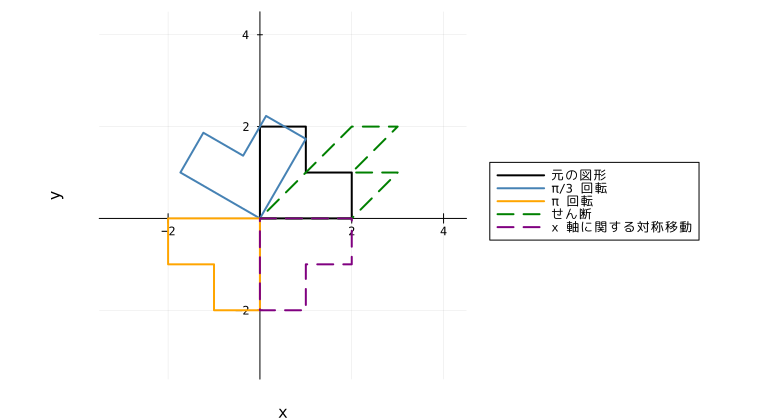

In [25]:
# 図形を変換して描く
shape = [[0, 0], [2, 0], [2, 1], [1, 1], [1, 2], [0, 2], [0, 0]]       # L 字形
draw!(pts; kw...) = plot!(first.(pts), last.(pts); lw=2, kw...)

plot(; aspect_ratio=1, xlims=(-3.5, 4.5), ylims=(-3.5, 4.5), framestyle=:origin, legend=:outerright, xlabel="x", ylabel="y", size=(760, 420))
draw!(shape; color=:black, label="元の図形")
draw!([R(π / 3) * p for p in shape]; color=:steelblue, label="π/3 回転")
draw!([R(π) * p for p in shape]; color=:orange, label="π 回転")
draw!([[1 1; 0 1] * p for p in shape]; color=:green, ls=:dash, label="せん断")
draw!([[1 0; 0 -1] * p for p in shape]; color=:purple, ls=:dash, label="x 軸に関する対称移動")

### 面積の拡大率と行列式

1 次変換で図形の面積は $|\det A|$ 倍になります。単位正方形の像（平行四辺形）の面積で確かめます。

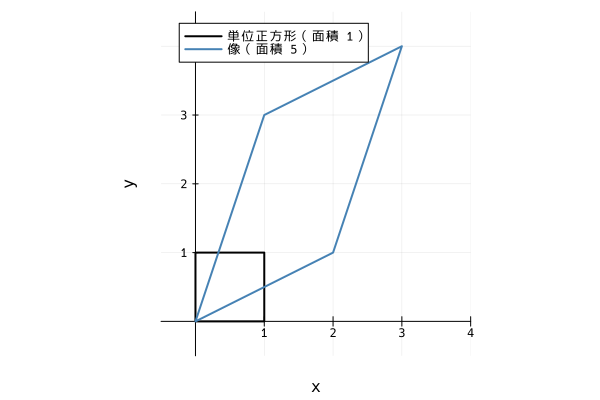

In [26]:
T = "{{2, 1}, {1, 3}}"
dTw = calc("Det[$T]"; lhs="\\det A")
calc("Area[Parallelogram[{0, 0}, {$T.{1, 0}, $T.{0, 1}}]]"; lhs="\\text{像の面積}")

square = [[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]]
plot(; aspect_ratio=1, xlims=(-0.5, 4), ylims=(-0.5, 4.5), framestyle=:origin, legend=:topleft, xlabel="x", ylabel="y")
draw!(square; color=:black, label="単位正方形（面積 1）")
draw!([[2 1; 1 3] * p for p in square]; color=:steelblue, label="像（面積 $(to_value(dTw))）")

### 直線に関する対称移動・正射影

直線 $y = mx$ に関する対称移動の行列を，Wolfram で文字のまま求めます（`ReflectionMatrix` に法線ベクトルを渡す）。  
`ComplexExpand` は，文字 $m$ を実数とみなして整理するために付けています。

In [27]:
Fw = calc("Simplify[ComplexExpand[ReflectionMatrix[{m, -1}]]]"; lhs="\\text{直線 } y = mx \\text{ に関する対称移動}")
calc("Simplify[ComplexExpand[ReflectionMatrix[{m, -1}].ReflectionMatrix[{m, -1}]]]"; lhs="\\text{2 回行うと}")

refl = to_matrix_function(Fw, :m)
refl(1), refl(2 // 1)                           # y = x：x と y の入れかえ，y = 2x：成分は分数

([0 1; 1 0], Rational{Int64}[-3//5 4//5; 4//5 3//5])

## 7. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **行列の積は `.`**：Wolfram で `A B` や `A * B` と書くと成分ごとの積になります。`A^2` も成分ごとの 2 乗なので，`MatrixPower[A, 2]` または `A.A` を使います。
- **固有ベクトルは行で返る**：`Eigenvectors[A]` の各行が固有ベクトルです。列に並べるには `Transpose` します。
- **3 次以上の固有値**：根号で簡単に書けないことがあります（`Root[...]` で返る）。`N[Eigenvalues[A]]` で数値にするか，Julia の `eigen` を使います。
- **逆行列がない**：`Inverse` は警告を出して未評価のまま返ります。先に `Det` を確かめます。

In [28]:
calc("{{1, 2}, {3, 4}} {{1, 2}, {3, 4}}"; lhs="A * A\\ \\text{（成分ごとの積）}")
calc("{{1, 2}, {3, 4}}.{{1, 2}, {3, 4}}"; lhs="A . A\\ \\text{（行列の積）}");

In [29]:
# 3 次の行列で固有値が根号で簡単に書けない例：数値にする
c3 = "{{1, 2, 0}, {0, 1, 3}, {1, 0, 1}}"
ev = weval(wparse("Eigenvalues[$c3]"))
println("厳密な固有値に Root を含むか： ", hasroot(ev))

to_value(weval(wparse("N[Eigenvalues[$c3]]"))), eigen([1 2 0; 0 1 3; 1 0 1]).values

厳密な固有値に Root を含むか： true


(ComplexF64[2.8171205928321394 + 0.0im, 0.09143970358393017 + 1.5736725951324724im, 0.09143970358393017 - 1.5736725951324724im], ComplexF64[0.09143970358393036 - 1.5736725951324726im, 0.09143970358393036 + 1.5736725951324726im, 2.81712059283214 + 0.0im])